# 03 — Combined Modeling: General + Format Features
## Does adding format features improve prediction?

In [1]:
import sys, json, warnings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 6)

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

df = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'format_dataset.parquet')

with open(PROJECT_ROOT / 'general_features_reference.json', 'r', encoding='utf-8') as f:
    gen_ref = json.load(f)
general_names = [f['name'] for c in gen_ref['categories'] for f in c['features']]
general_available = [f for f in general_names if f in df.columns]

with open(PROJECT_ROOT / 'format_features_reference.json', 'r', encoding='utf-8') as f:
    fmt_ref = json.load(f)
format_names = [f['name'] for f in fmt_ref['features']]
format_available = [f for f in format_names if f in df.columns]

print(f'Dataset: {len(df)} posts')
print(f'General features: {len(general_available)}')
print(f'Format features: {len(format_available)}')
print(f'Combined: {len(general_available) + len(format_available)}')

Dataset: 140 posts
General features: 62
Format features: 15
Combined: 77


In [2]:
def encode_feature_matrix(df, feature_list):
    X = df[feature_list].copy()
    for col in X.columns:
        numeric = pd.to_numeric(X[col], errors='coerce')
        if numeric.notna().sum() > len(X) * 0.5:
            X[col] = numeric
        else:
            X[col] = LabelEncoder().fit_transform(X[col].astype(str))
    X = X.fillna(X.median())
    return X

X_general = encode_feature_matrix(df, general_available)
X_format = encode_feature_matrix(df, format_available)
X_combined = pd.concat([X_general, X_format], axis=1)

print(f'X_general: {X_general.shape}')
print(f'X_format:  {X_format.shape}')
print(f'X_combined: {X_combined.shape}')

X_general: (140, 62)
X_format:  (140, 15)
X_combined: (140, 77)


## Model Comparison: General vs Format vs Combined

In [3]:
targets = ['reach', 'views', 'likes', 'shares', 'saved']
available_targets = [t for t in targets if t in df.columns]

results = []

for target in available_targets:
    y = pd.to_numeric(df[target], errors='coerce')
    mask = y.notna()
    y_clean = y[mask]

    for name, X in [('General (62)', X_general), ('Format (15)', X_format), ('Combined (77)', X_combined)]:
        X_clean = X[mask]

        rf = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)
        cv_r2 = cross_val_score(rf, X_clean, y_clean, cv=5, scoring='r2')
        cv_mae = cross_val_score(rf, X_clean, y_clean, cv=5, scoring='neg_mean_absolute_error')

        results.append({
            'target': target,
            'features': name,
            'R2_mean': cv_r2.mean(),
            'R2_std': cv_r2.std(),
            'MAE_mean': -cv_mae.mean(),
            'MAE_std': cv_mae.std(),
        })
        print(f'{target:8s} | {name:18s} | R²={cv_r2.mean():+.3f} (±{cv_r2.std():.3f}) | MAE={-cv_mae.mean():.0f}')
    print()

results_df = pd.DataFrame(results)

reach    | General (62)       | R²=-75.231 (±148.033) | MAE=12670


reach    | Format (15)        | R²=-88.193 (±175.216) | MAE=11645


reach    | Combined (77)      | R²=-52.371 (±102.506) | MAE=12429



views    | General (62)       | R²=-42.392 (±81.981) | MAE=17217


views    | Format (15)        | R²=-58.027 (±114.729) | MAE=15640


...

shares   | Format (15)        | R²=-27.486 (±52.921) | MAE=348


shares   | Combined (77)      | R²=-53.456 (±104.169) | MAE=423



saved    | General (62)       | R²=-22.184 (±42.554) | MAE=101


saved    | Format (15)        | R²=-37.099 (±72.473) | MAE=97


saved    | Combined (77)      | R²=-21.501 (±41.012) | MAE=102



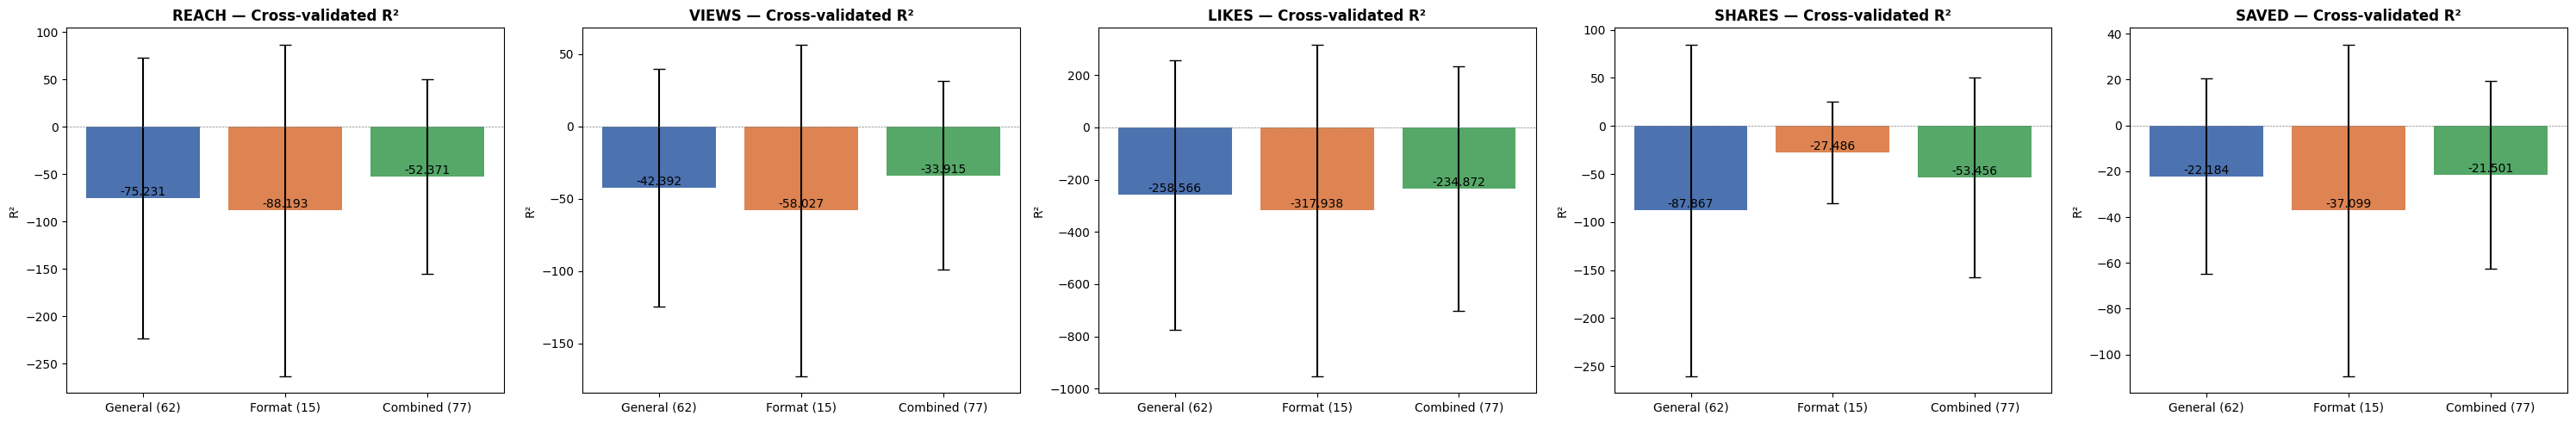

In [4]:
fig, axes = plt.subplots(1, len(available_targets), figsize=(6 * len(available_targets), 5))
if len(available_targets) == 1:
    axes = [axes]

colors = {'General (62)': '#4c72b0', 'Format (15)': '#dd8452', 'Combined (77)': '#55a868'}

for ax, target in zip(axes, available_targets):
    subset = results_df[results_df['target'] == target]
    bars = ax.bar(subset['features'], subset['R2_mean'],
                  yerr=subset['R2_std'], capsize=5,
                  color=[colors[f] for f in subset['features']])
    ax.set_title(f'{target.upper()} — Cross-validated R²', fontweight='bold')
    ax.set_ylabel('R²')
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
    for bar, val in zip(bars, subset['R2_mean']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## Improvement from Adding Format Features

In [5]:
print('Does adding format features improve prediction?\n')
for target in available_targets:
    subset = results_df[results_df['target'] == target]
    r2_general = subset[subset['features'] == 'General (62)']['R2_mean'].values[0]
    r2_combined = subset[subset['features'] == 'Combined (77)']['R2_mean'].values[0]
    r2_format = subset[subset['features'] == 'Format (15)']['R2_mean'].values[0]
    delta = r2_combined - r2_general
    verdict = 'YES' if delta > 0.01 else ('MARGINAL' if delta > 0 else 'NO')
    print(f'{target:8s}: General={r2_general:+.3f}  Format-only={r2_format:+.3f}  Combined={r2_combined:+.3f}  Delta={delta:+.3f}  -> {verdict}')

Does adding format features improve prediction?

reach   : General=-75.231  Format-only=-88.193  Combined=-52.371  Delta=+22.860  -> YES
views   : General=-42.392  Format-only=-58.027  Combined=-33.915  Delta=+8.477  -> YES
likes   : General=-258.566  Format-only=-317.938  Combined=-234.872  Delta=+23.694  -> YES
shares  : General=-87.867  Format-only=-27.486  Combined=-53.456  Delta=+34.411  -> YES
saved   : General=-22.184  Format-only=-37.099  Combined=-21.501  Delta=+0.682  -> YES
